# Evaluation on unseen recordings

The trained model (`models/hmm_parameters.json`) is tested on two new recordings that were not used
for training, features, normalization or the choice of the feature set. Each recording moves through
all four activities in one continuous take. Take 1 goes Still, Standing, Walking, Jumping. Take 2
goes Jumping, Walking, Standing, Still. They were recorded on 2026-10-30 with the same phone, app
and sampling rate as the training data.

**What the model sees.** Only the sensor readings. Each take is cut into windows of 255 readings
(5.1 s), the same length as in training; the same 12 features are computed, scaled with the saved
training scaler (never refitted), and the eight features chosen during training are given to the
model. The model never receives the switch times.

**What the grading uses.** `data/raw_unseen/answer_key.csv` lists when each activity was performed.
The order comes from the person who recorded, and the switch times were read from the movement
levels and checked against the taps on the phone's annotation button. The key was written before the
model was run on these takes. Because the key is only accurate to about one or two seconds, a window
is graded only when it lies completely inside an activity, with a margin of 1.5 s from each switch.
Windows that touch a switch are still decoded but not scored.

**Decoding.** The windows of a take form one sequence. Viterbi decoding finds the most probable
sequence of activities for the whole take, using the transition matrix. For comparison, the same
windows are also classified one at a time from the emission probabilities alone, which shows what
the transition matrix adds.

**Cut points.** The first 5 s of each take are skipped, as in training. One cut of the take into
consecutive windows gives only about a dozen graded windows, and only one for Standing. The take is
therefore also cut starting 1, 2, 3 and 4 s later. These five cuts are the same recording seen
from different positions, so their windows overlap and are not independent. The tables show both:
a single cut (independent windows, small numbers) and the five cuts together (more windows, but
correlated).

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch, Rectangle

sys.path.insert(0, str(Path("../src").resolve()))
from gaussian_hmm import GaussianHMM
from window_features import apply_scaler, window_features

UNSEEN_DIR = Path("../data/raw_unseen")
FEATURES_DIR = Path("../data/features")
MODELS_DIR = Path("../models")
FIGURES_DIR = Path("../figures")
RESULTS_DIR = Path("../results")
RESULTS_DIR.mkdir(exist_ok=True)

TAKES = ["test_take_1_still_first", "test_take_2_jumping_first"]
WINDOW_ROWS = 255          # 5.1 s at 50 Hz, as in training
TRIM_SECONDS = 5           # settling motion at the start of a take, as in training
MARGIN_SECONDS = 1.5       # a graded window must stay this far from every switch
OFFSETS_SECONDS = [0, 1, 2, 3, 4]
AXES = ["x", "y", "z"]
COLUMNS = ["time_s"] + [f"acc_{a}" for a in AXES] + [f"gyro_{a}" for a in AXES]
COLORS = {"Still": "#2a78d6", "Standing": "#1baf7a", "Walking": "#eb6834", "Jumping": "#9b4dca"}

saved = json.loads((MODELS_DIR / "hmm_parameters.json").read_text())
ACTIVITIES = saved["activities"]
MODEL_FEATURES = saved["features"]
model = GaussianHMM(len(ACTIVITIES), len(MODEL_FEATURES), variance_floor=saved["variance_floor"])
model.set_parameters(saved["start"], saved["transitions"], saved["means"], saved["variances"])
scaler = json.loads((FEATURES_DIR / "scaler.json").read_text())
answer_key = pd.read_csv(UNSEEN_DIR / "answer_key.csv")

print("states:", ACTIVITIES)
print("features given to the model:", MODEL_FEATURES)
answer_key

states: ['Still', 'Standing', 'Walking', 'Jumping']
features given to the model: ['acc_std', 'acc_corr', 'acc_jerk_ratio', 'acc_dom_freq', 'acc_low_freq_share', 'gyro_corr', 'gyro_jerk_ratio', 'gyro_dom_freq']


,take,activity,start_s,end_s
0,test_take_1_still_first,Still,0.0,16.5
1,test_take_1_still_first,Standing,21.0,34.0
2,test_take_1_still_first,Walking,34.0,46.0
3,test_take_1_still_first,Jumping,46.0,62.0
4,test_take_2_jumping_first,Jumping,0.0,20.5
5,test_take_2_jumping_first,Walking,20.5,40.0
6,test_take_2_jumping_first,Standing,42.0,50.5
7,test_take_2_jumping_first,Still,55.0,68.5


## Loading the two takes

The accelerometer and gyroscope files must line up row by row, exactly as for the training
recordings.

In [2]:
def load_recording(take):
    """Return one table with time_s and the six sensor columns of a take."""
    acc = pd.read_csv(UNSEEN_DIR / take / "Accelerometer.csv")
    gyro = pd.read_csv(UNSEEN_DIR / take / "Gyroscope.csv")
    if len(acc) != len(gyro) or not (acc["time"].values == gyro["time"].values).all():
        raise ValueError(f"{take}: accelerometer and gyroscope timestamps do not match")
    table = pd.DataFrame({"time_s": acc["seconds_elapsed"]})
    for axis in AXES:
        table[f"acc_{axis}"] = acc[axis]
    for axis in AXES:
        table[f"gyro_{axis}"] = gyro[axis]
    return table[COLUMNS]


recordings = {take: load_recording(take) for take in TAKES}
pd.DataFrame({
    "rows": {t: len(r) for t, r in recordings.items()},
    "duration_s": {t: round(r["time_s"].iloc[-1], 1) for t, r in recordings.items()},
    "median_step_ms": {t: round(1000 * r["time_s"].diff().median(), 2) for t, r in recordings.items()},
})

,rows,duration_s,median_step_ms
test_take_1_still_first,3079,61.8,20.03
test_take_2_jumping_first,3391,68.0,20.03


## Cutting, scoring and decoding

`decode_take` cuts a take into consecutive windows, computes and scales the features, and returns
the Viterbi path and the window-by-window classification, together with the true activity from the
answer key (or nothing if the window touches a switch).

In [3]:
def tile_windows(table, offset_seconds):
    """Consecutive, non-overlapping windows of 255 readings, after the trim and an optional shift."""
    first = int(np.argmax(table["time_s"].to_numpy() >= TRIM_SECONDS + offset_seconds))
    count = (len(table) - first) // WINDOW_ROWS
    return [
        table.iloc[first + i * WINDOW_ROWS:first + (i + 1) * WINDOW_ROWS].reset_index(drop=True)
        for i in range(count)
    ]


def true_activity(take, start_s, end_s):
    """The activity of a window if it lies inside one activity with the margin, otherwise None."""
    for row in answer_key[answer_key["take"] == take].itertuples():
        if start_s >= row.start_s + MARGIN_SECONDS and end_s <= row.end_s - MARGIN_SECONDS:
            return row.activity
    return None


def decode_take(take, offset_seconds):
    """Features, true activity and the two predictions for every window of one cut of a take."""
    windows = tile_windows(recordings[take], offset_seconds)
    assert all(len(w) == WINDOW_ROWS for w in windows)
    normalized = apply_scaler(pd.DataFrame([window_features(w) for w in windows]), scaler)
    observations = normalized[MODEL_FEATURES].to_numpy()
    assert np.isfinite(observations).all()
    path, _ = model.viterbi(observations)
    alone = model.log_emission(observations).argmax(axis=1)
    starts = [w["time_s"].iloc[0] for w in windows]
    ends = [w["time_s"].iloc[-1] for w in windows]
    table = pd.DataFrame({
        "take": take, "offset_s": offset_seconds, "window": range(1, len(windows) + 1),
        "start_s": starts, "end_s": ends,
        "truth": [true_activity(take, s, e) for s, e in zip(starts, ends)],
        "hmm": [ACTIVITIES[i] for i in path],
        "windows_alone": [ACTIVITIES[i] for i in alone],
    })
    return pd.concat([table, normalized[MODEL_FEATURES].add_prefix("z_")], axis=1)


predictions = pd.concat(
    [decode_take(take, offset) for take in TAKES for offset in OFFSETS_SECONDS], ignore_index=True
)
predictions.to_csv(RESULTS_DIR / "test_window_predictions.csv", index=False)
one_cut = predictions[predictions["offset_s"] == 0]
pd.DataFrame({
    "windows": predictions.groupby("offset_s").size(),
    "graded": predictions[predictions["truth"].notna()].groupby("offset_s").size(),
})

,windows,graded
offset_s,,
0,23,9
1,22,9
2,21,10
3,21,11
4,21,8


### One cut (offset 0): every window, what it truly was, and what the model said

A missing true activity means that the window touches a switch and is not graded.

In [4]:
one_cut[["take", "window", "start_s", "end_s", "truth", "hmm", "windows_alone"]].round(1).reset_index(drop=True)

,take,window,start_s,end_s,truth,hmm,windows_alone
0,test_take_1_still_first,1,5.0,10.1,Still,Still,Still
1,test_take_1_still_first,2,10.1,15.2,NaN,Still,Still
2,test_take_1_still_first,3,15.2,20.3,NaN,Walking,Walking
3,test_take_1_still_first,4,20.3,25.4,NaN,Standing,Standing
4,test_take_1_still_first,5,25.5,30.5,Standing,Standing,Standing
5,test_take_1_still_first,6,30.6,35.6,NaN,Standing,Standing
6,test_take_1_still_first,7,35.7,40.8,Walking,Walking,Walking
7,test_take_1_still_first,8,40.8,45.9,NaN,Walking,Walking
8,test_take_1_still_first,9,45.9,51.0,NaN,Jumping,Jumping
9,test_take_1_still_first,10,51.0,56.1,Jumping,Jumping,Jumping


## Sensitivity, specificity and accuracy

For each activity, the windows of that activity are the positives and all other graded windows are
the negatives.

- **Sensitivity** is the share of the activity's windows that the model labeled correctly: TP / (TP + FN).
- **Specificity** is the share of the other windows that the model did not label as this activity: TN / (TN + FP).
- **Accuracy (one vs rest)** is the share of all graded windows that are right for this activity alone.
- **Overall accuracy** is the share of all graded windows labeled correctly. It is one number for the model, repeated in each row.

In [5]:
def confusion(frame, column):
    """Confusion matrix of the graded windows: rows are the true activity, columns the prediction."""
    graded = frame[frame["truth"].notna()]
    matrix = np.zeros((len(ACTIVITIES), len(ACTIVITIES)), dtype=int)
    for truth, predicted in zip(graded["truth"], graded[column]):
        matrix[ACTIVITIES.index(truth), ACTIVITIES.index(predicted)] += 1
    return matrix


def metrics_table(matrix):
    """Samples, sensitivity, specificity and accuracy per activity from a confusion matrix."""
    total = matrix.sum()
    rows = []
    for i, activity in enumerate(ACTIVITIES):
        tp = matrix[i, i]
        fn = matrix[i].sum() - tp
        fp = matrix[:, i].sum() - tp
        tn = total - tp - fn - fp
        rows.append({
            "activity": activity,
            "samples": int(matrix[i].sum()),
            "sensitivity": tp / (tp + fn) if tp + fn else np.nan,
            "specificity": tn / (tn + fp) if tn + fp else np.nan,
            "accuracy (one vs rest)": (tp + tn) / total,
        })
    table = pd.DataFrame(rows)
    table["overall accuracy"] = np.trace(matrix) / total
    return table


VARIANTS = {
    "HMM with Viterbi, five cuts together": (predictions, "hmm"),
    "HMM with Viterbi, one cut": (one_cut, "hmm"),
    "Windows classified alone, five cuts together": (predictions, "windows_alone"),
    "Windows classified alone, one cut": (one_cut, "windows_alone"),
}
matrices = {name: confusion(frame, column) for name, (frame, column) in VARIANTS.items()}
tables = {name: metrics_table(matrix) for name, matrix in matrices.items()}
for name, table in tables.items():
    print(f"{name}  ({matrices[name].sum()} graded windows)")
    display(table.round(3).set_index("activity"))

long_form = pd.concat([t.assign(variant=name) for name, t in tables.items()], ignore_index=True)
long_form.to_csv(RESULTS_DIR / "test_metrics.csv", index=False)

HMM with Viterbi, five cuts together  (47 graded windows)


,samples,sensitivity,specificity,accuracy (one vs rest),overall accuracy
activity,,,,,
Still,10,1.0,1.0,1.0,1.0
Standing,5,1.0,1.0,1.0,1.0
Walking,15,1.0,1.0,1.0,1.0
Jumping,17,1.0,1.0,1.0,1.0


HMM with Viterbi, one cut  (9 graded windows)


,samples,sensitivity,specificity,accuracy (one vs rest),overall accuracy
activity,,,,,
Still,2,1.0,1.0,1.0,1.0
Standing,1,1.0,1.0,1.0,1.0
Walking,3,1.0,1.0,1.0,1.0
Jumping,3,1.0,1.0,1.0,1.0


Windows classified alone, five cuts together  (47 graded windows)


,samples,sensitivity,specificity,accuracy (one vs rest),overall accuracy
activity,,,,,
Still,10,1.0,1.0,1.0,1.0
Standing,5,1.0,1.0,1.0,1.0
Walking,15,1.0,1.0,1.0,1.0
Jumping,17,1.0,1.0,1.0,1.0


Windows classified alone, one cut  (9 graded windows)


,samples,sensitivity,specificity,accuracy (one vs rest),overall accuracy
activity,,,,,
Still,2,1.0,1.0,1.0,1.0
Standing,1,1.0,1.0,1.0,1.0
Walking,3,1.0,1.0,1.0,1.0
Jumping,3,1.0,1.0,1.0,1.0


### Check of the numbers by a second route

The overall accuracy is recomputed directly from the prediction table, without the confusion
matrix, and must match.

In [6]:
for name, (frame, column) in VARIANTS.items():
    graded = frame[frame["truth"].notna()]
    direct = (graded["truth"] == graded[column]).mean()
    from_matrix = np.trace(matrices[name]) / matrices[name].sum()
    assert abs(direct - from_matrix) < 1e-12, name
    print(f"{name}: direct {direct:.4f} | from the matrix {from_matrix:.4f}")

HMM with Viterbi, five cuts together: direct 1.0000 | from the matrix 1.0000
HMM with Viterbi, one cut: direct 1.0000 | from the matrix 1.0000
Windows classified alone, five cuts together: direct 1.0000 | from the matrix 1.0000
Windows classified alone, one cut: direct 1.0000 | from the matrix 1.0000


### Each take separately (HMM with Viterbi, five cuts together)

In [7]:
for take in TAKES:
    matrix = confusion(predictions[predictions["take"] == take], "hmm")
    print(take, "-", matrix.sum(), "graded windows")
    display(metrics_table(matrix).round(3).set_index("activity"))

test_take_1_still_first - 21 graded windows


,samples,sensitivity,specificity,accuracy (one vs rest),overall accuracy
activity,,,,,
Still,5,1.0,1.0,1.0,1.0
Standing,4,1.0,1.0,1.0,1.0
Walking,4,1.0,1.0,1.0,1.0
Jumping,8,1.0,1.0,1.0,1.0


test_take_2_jumping_first - 26 graded windows


,samples,sensitivity,specificity,accuracy (one vs rest),overall accuracy
activity,,,,,
Still,5,1.0,1.0,1.0,1.0
Standing,1,1.0,1.0,1.0,1.0
Walking,11,1.0,1.0,1.0,1.0
Jumping,9,1.0,1.0,1.0,1.0


## Confusion matrix

Rows are the true activity, columns are what the model said. The left matrix uses the HMM with
Viterbi decoding; the right one classifies each window alone. Both use the five cuts together.

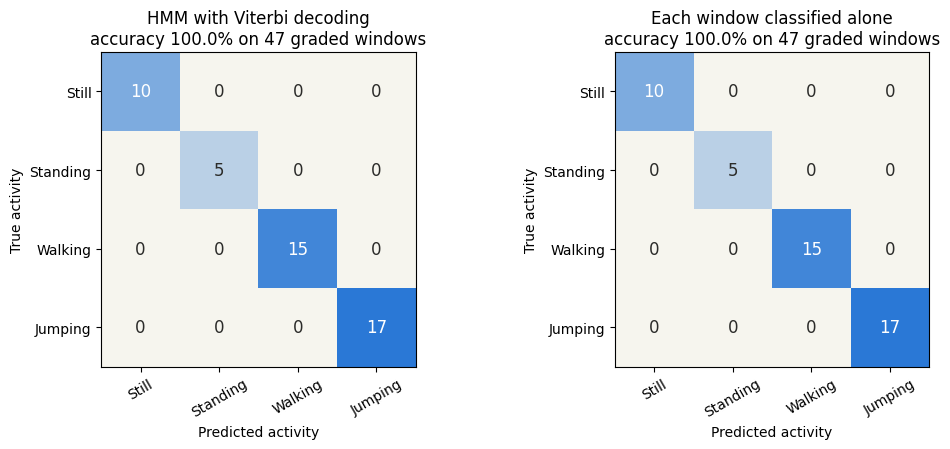

In [8]:
def style_axes(ax):
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)


cmap = LinearSegmentedColormap.from_list("blues", ["#f6f5ee", "#2a78d6"])
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.6))
for ax, name, title in zip(
    axes,
    ["HMM with Viterbi, five cuts together", "Windows classified alone, five cuts together"],
    ["HMM with Viterbi decoding", "Each window classified alone"],
):
    matrix = matrices[name]
    ax.imshow(matrix, cmap=cmap, vmin=0, vmax=matrix.max())
    for i in range(len(ACTIVITIES)):
        for j in range(len(ACTIVITIES)):
            ax.text(j, i, matrix[i, j], ha="center", va="center",
                    color="white" if matrix[i, j] > 0.55 * matrix.max() else "#2c2c2a", fontsize=12)
    ax.set_xticks(range(len(ACTIVITIES)), ACTIVITIES, rotation=30)
    ax.set_yticks(range(len(ACTIVITIES)), ACTIVITIES)
    ax.set_xlabel("Predicted activity")
    ax.set_ylabel("True activity")
    ax.set_title(f"{title}\naccuracy {np.trace(matrix) / matrix.sum():.1%} on {matrix.sum()} graded windows")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "confusion_matrix_test.png", dpi=200, bbox_inches="tight")
plt.show()

## Decoded sequences

For each take: the movement level (standard deviation of the acceleration strength over one
second), the true activities from the answer key, the HMM decoding and the window-by-window
classification, all for the single cut at offset 0. Faded blocks are windows that touch a switch
and are not graded.

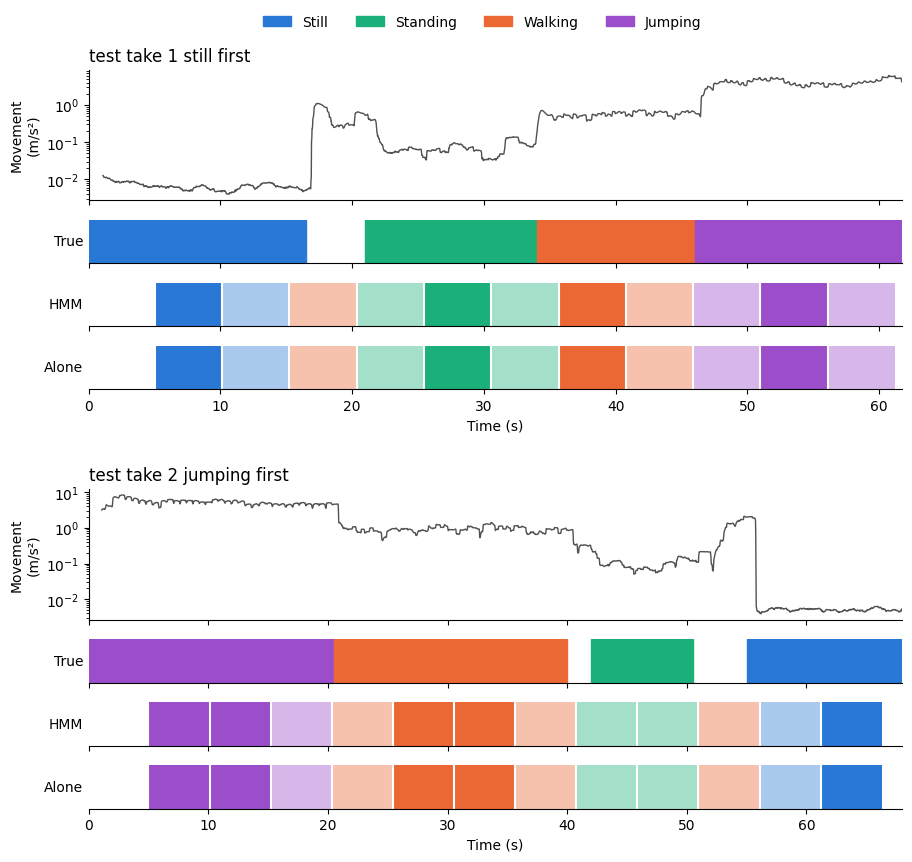

In [9]:
def movement_level(table):
    """Standard deviation of the acceleration strength over a one second moving window."""
    strength = np.sqrt((table[[f"acc_{a}" for a in AXES]] ** 2).sum(axis=1))
    return np.maximum(strength.rolling(50).std(), 1e-3)


fig = plt.figure(figsize=(10.5, 9.6))
grid = fig.add_gridspec(9, 1, height_ratios=[1.5, 0.5, 0.5, 0.5, 0.7, 1.5, 0.5, 0.5, 0.5], hspace=0.3)
for index, take in enumerate(TAKES):
    recording = recordings[take]
    first_row = 5 * index
    top = fig.add_subplot(grid[first_row])
    top.semilogy(recording["time_s"], movement_level(recording), color="#52514e", linewidth=1)
    top.set_ylabel("Movement\n(m/s²)")
    top.set_title(take.replace("_", " "), loc="left")
    style_axes(top)
    bands = [
        fig.add_subplot(grid[first_row + k], sharex=top) for k in (1, 2, 3)
    ]
    for ax, label in zip(bands, ["True", "HMM", "Alone"]):
        ax.set_ylim(0, 1)
        ax.set_yticks([])
        ax.set_ylabel(label, rotation=0, ha="right", va="center")
        for side in ["top", "right", "left"]:
            ax.spines[side].set_visible(False)
    for row in answer_key[answer_key["take"] == take].itertuples():
        bands[0].add_patch(Rectangle((row.start_s, 0), row.end_s - row.start_s, 1, color=COLORS[row.activity]))
    for row in one_cut[one_cut["take"] == take].itertuples():
        alpha = 1.0 if isinstance(row.truth, str) else 0.4
        for ax, value in zip(bands[1:], [row.hmm, row.windows_alone]):
            ax.add_patch(Rectangle((row.start_s, 0), row.end_s - row.start_s, 1,
                                   color=COLORS[value], alpha=alpha, linewidth=0))
            ax.plot([row.start_s, row.start_s], [0, 1], color="white", linewidth=1.5)
    top.set_xlim(0, recording["time_s"].iloc[-1])
    for ax in bands[:-1]:
        ax.tick_params(labelbottom=False)
    top.tick_params(labelbottom=False)
    bands[-1].set_xlabel("Time (s)")
fig.legend(handles=[Patch(color=c, label=a) for a, c in COLORS.items()], loc="upper center",
           ncol=4, frameon=False, bbox_to_anchor=(0.5, 0.95))
fig.savefig(FIGURES_DIR / "decoded_sequences_test.png", dpi=200, bbox_inches="tight")
plt.show()

## Transition matrix

The trained probability of moving from the activity in each row to the activity in each column
between two consecutive windows. The off-diagonal numbers come mainly from the assumption described
in `hmm_training.ipynb` (the training recordings contain no switches), not from observed switching.

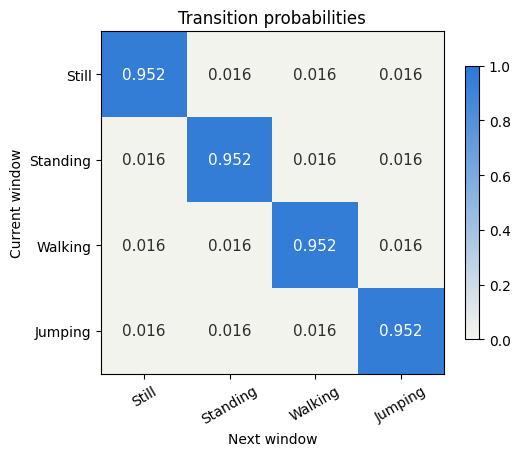

start probabilities: {'Still': np.float64(0.25), 'Standing': np.float64(0.25), 'Walking': np.float64(0.25), 'Jumping': np.float64(0.25)}


In [10]:
transitions = np.array(saved["transitions"])
fig, ax = plt.subplots(figsize=(5.6, 4.6))
image = ax.imshow(transitions, cmap=cmap, vmin=0, vmax=1)
for i in range(len(ACTIVITIES)):
    for j in range(len(ACTIVITIES)):
        ax.text(j, i, f"{transitions[i, j]:.3f}", ha="center", va="center",
                color="white" if transitions[i, j] > 0.55 else "#2c2c2a", fontsize=11)
ax.set_xticks(range(len(ACTIVITIES)), ACTIVITIES, rotation=30)
ax.set_yticks(range(len(ACTIVITIES)), ACTIVITIES)
ax.set_xlabel("Next window")
ax.set_ylabel("Current window")
ax.set_title("Transition probabilities")
fig.colorbar(image, ax=ax, shrink=0.8)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "transition_matrix_heatmap.png", dpi=200, bbox_inches="tight")
plt.show()
print("start probabilities:", dict(zip(ACTIVITIES, np.round(saved["start"], 3))))

## Emission distributions

For each of the eight features, the black marks show the average and one standard deviation that the
model learned for each activity (normalized units). The colored dots are the graded test windows,
placed at the activity they truly belong to. A dot far outside its bar is a window that does not
look like the training data of its own activity.

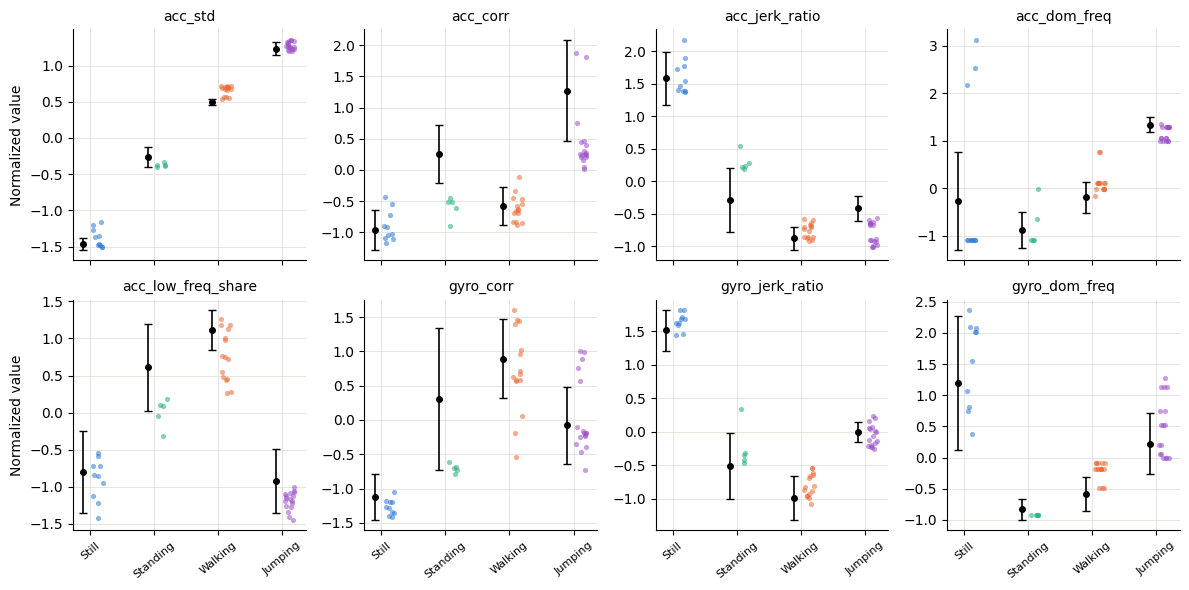

In [11]:
graded = predictions[predictions["truth"].notna()]
means, spreads = np.array(saved["means"]), np.sqrt(np.array(saved["variances"]))
rng = np.random.default_rng(0)
fig, axes = plt.subplots(2, 4, figsize=(12, 6), sharex=True)
for ax, (d, feature) in zip(axes.ravel(), enumerate(MODEL_FEATURES)):
    for i, activity in enumerate(ACTIVITIES):
        values = graded.loc[graded["truth"] == activity, f"z_{feature}"]
        ax.scatter(i + 0.12 + rng.uniform(-0.08, 0.08, len(values)), values, s=14, alpha=0.55,
                   color=COLORS[activity], linewidths=0)
        ax.errorbar(i - 0.1, means[i, d], yerr=spreads[i, d], fmt="o", color="black",
                    markersize=4, capsize=3, linewidth=1.2)
    ax.set_title(feature, fontsize=10)
    ax.set_xticks(range(len(ACTIVITIES)), ACTIVITIES, rotation=40, fontsize=8)
    ax.grid(color="#e1e0d9", linewidth=0.6)
    ax.set_axisbelow(True)
    style_axes(ax)
axes[0, 0].set_ylabel("Normalized value")
axes[1, 0].set_ylabel("Normalized value")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "emission_distributions.png", dpi=200, bbox_inches="tight")
plt.show()

## Switches found by the decoding

The number of times the decoded activity changes between consecutive windows, against the number of
changes in the answer key (three per take).

In [12]:
rows = []
for take in TAKES:
    frame = one_cut[one_cut["take"] == take]
    rows.append({
        "take": take,
        "windows": len(frame),
        "switches in the HMM decoding": int((frame["hmm"] != frame["hmm"].shift()).iloc[1:].sum()),
        "switches with windows alone": int((frame["windows_alone"] != frame["windows_alone"].shift()).iloc[1:].sum()),
        "switches in the answer key": 3,
    })
pd.DataFrame(rows).set_index("take")

,windows,switches in the HMM decoding,switches with windows alone,switches in the answer key
take,,,,
test_take_1_still_first,11,4,4,3
test_take_2_jumping_first,12,4,4,3


## Does the transition matrix change any decision?

The windows where the HMM with Viterbi decoding and the window-by-window classification disagree,
over all five cuts.

In [13]:
disagree = predictions[predictions["hmm"] != predictions["windows_alone"]]
print(f"{len(disagree)} of {len(predictions)} windows differ; "
      f"{int(disagree['truth'].notna().sum())} of them are graded")
disagree[["take", "offset_s", "window", "start_s", "end_s", "truth", "hmm", "windows_alone"]].round(1)

2 of 108 windows differ; 0 of them are graded


,take,offset_s,window,start_s,end_s,truth,hmm,windows_alone
23,test_take_1_still_first,2,3,17.2,22.3,NaN,Standing,Walking
94,test_take_2_jumping_first,3,9,48.9,54.0,NaN,Standing,Walking


## Robustness to the margin around each switch

The answer key is accurate to about one or two seconds, so the grading is repeated with other margins.
The predictions do not change; only the set of graded windows does. This is a check of the grading, and the
margin of 1.5 s fixed at the start is the one reported.

In [14]:
rows = []
for margin in [0.0, 1.5, 3.0, 4.0]:
    truth = [
        next((r.activity for r in answer_key[answer_key["take"] == take].itertuples()
              if start >= r.start_s + margin and end <= r.end_s - margin), None)
        for take, start, end in zip(predictions["take"], predictions["start_s"], predictions["end_s"])
    ]
    frame = predictions.assign(truth=truth)
    graded = frame[frame["truth"].notna()]
    rows.append({
        "margin (s)": margin,
        "graded windows": len(graded),
        "Standing windows": int((graded["truth"] == "Standing").sum()),
        "HMM errors": int((graded["truth"] != graded["hmm"]).sum()),
        "windows-alone errors": int((graded["truth"] != graded["windows_alone"]).sum()),
    })
pd.DataFrame(rows).set_index("margin (s)")

,graded windows,Standing windows,HMM errors,windows-alone errors
margin (s),,,,
0.0,67,11,0,0
1.5,47,5,0,0
3.0,30,2,0,0
4.0,19,0,0,0
